In [41]:
!pip install qiskit > out

import numpy as np
from qiskit import QuantumCircuit  # (imported for parity with a QC workflow; not used in this cell)
import matplotlib.pyplot as plt

import numpy as np

def binary_to_integer(vOutput):
    """
    Convert binary vector 'vOutput' to an integer.
    """
    vPows = 2**np.array(range(len(vOutput)))  # Array of powers of 2
    vPows = vPows[::-1]                       # Reverse to match binary order (MSB on the left)
    return np.dot(vOutput, vPows)             # Dot product to convert to an integer

vOutput = np.array((1, 0, 1, 0))
print(binary_to_integer(vOutput)) 

10


A

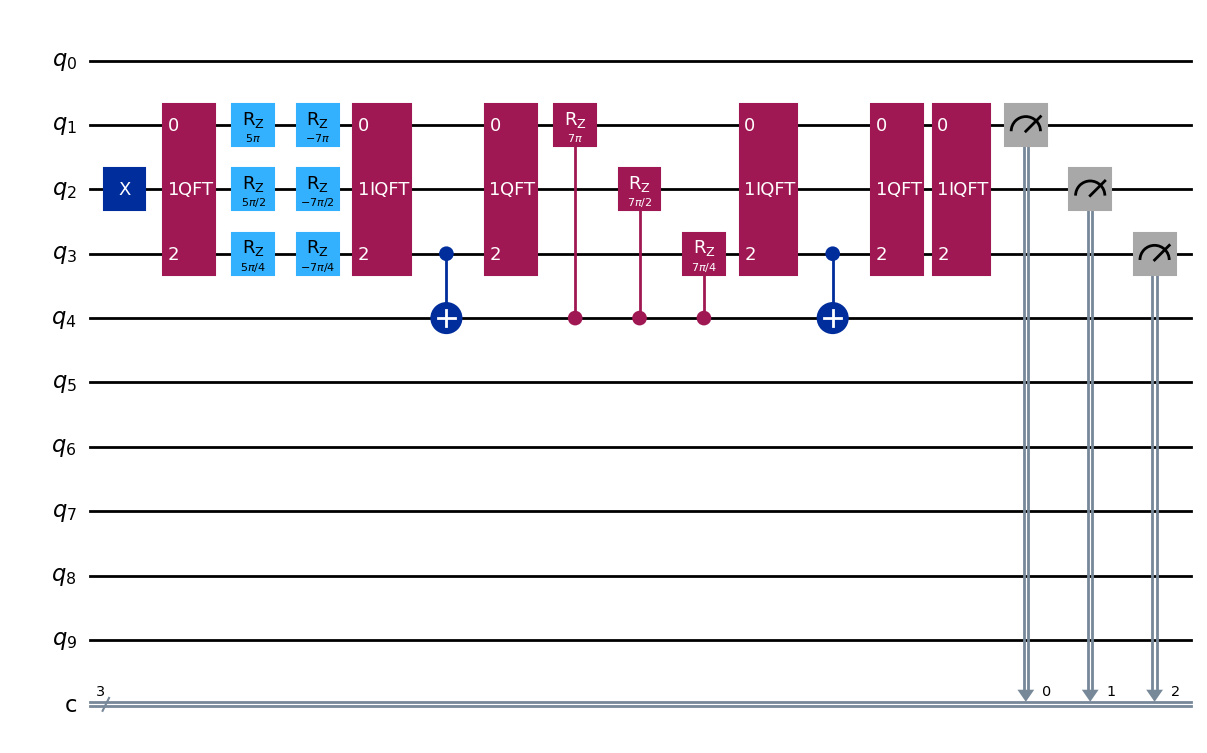

In [ ]:
from qiskit import QuantumCircuit

def set_classical_value_to_register(qc: QuantumCircuit, x: int, wires):
    """
    Prepare |x> on 'wires' (basis state). 
    Least significant bit (LSB) is at the *rightmost* wire in 'wires'.
    """
    n = len(wires)
    bits = [(x >> i) & 1 for i in range(n)][::-1]  # MSB ... LSB aligned with wires left->right
    for b, w in zip(bits, wires):
        if b == 1:
            qc.x(w)

def copy_register(qc: QuantumCircuit, src_wires, dst_wires):
    """Copy basis state: dst ^= src (CNOT per bit)."""
    for s, d in zip(src_wires, dst_wires):
        qc.cx(s, d)

def clear_register_with_copy(qc: QuantumCircuit, src_wires, dst_wires):
    """Uncompute the copy: dst ^= src (CNOT per bit again)."""
    for s, d in zip(src_wires, dst_wires):
        qc.cx(s, d)


from qiskit.visualization import circuit_drawer

circuit_drawer(qc, output='mpl')

B

C:\Users\Sennai\AppData\Local\Temp\ipykernel_26276\2000039801.py:26: DeprecationWarning: The class ``qiskit.circuit.library.basis_change.qft.QFT`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. ('Use qiskit.circuit.library.QFTGate or qiskit.synthesis.qft.synth_qft_full instead, for access to all previous arguments.',)
  qc.compose(QFT(n, do_swaps=False), qubits=a, inplace=True)
C:\Users\Sennai\AppData\Local\Temp\ipykernel_26276\2000039801.py:35: DeprecationWarning: The class ``qiskit.circuit.library.basis_change.qft.QFT`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. ('Use qiskit.circuit.library.QFTGate or qiskit.synthesis.qft.synth_qft_full instead, for access to all previous arguments.',)
  qc.compose(QFT(n, do_swaps=False).inverse(), qubits=a, inplace=True)
C:\Users\Sennai\AppData\Local\Temp\ipykernel_26276\2000039801.py:37: DeprecationWarning: The class ``qiskit.circuit.library.basis_change.qft.QFT`` is deprecated as of Qiskit 2.1. It will be 

4 + 5 mod 7 = 2


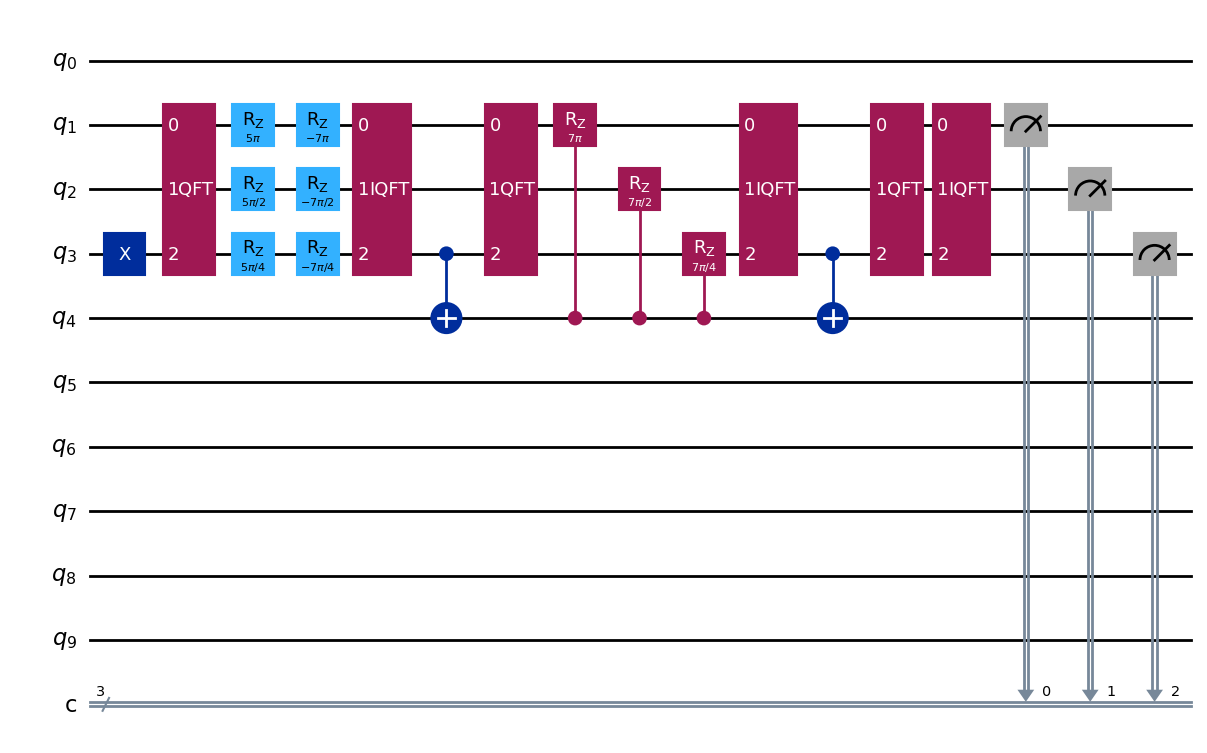

In [43]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.circuit.library import QFT

def _phase_add(qc: QuantumCircuit, regs, k: int):  # In Fourier basis: a <- a + k
    for j, q in enumerate(regs):
        qc.rz(k * np.pi / (2**j), q)

def add_const(qc: QuantumCircuit, a, k: int, in_std_basis: bool = True):
    n = len(a)
    if in_std_basis:
        qc.compose(QFT(n, do_swaps=False), qubits=a, inplace=True)
    _phase_add(qc, a, k)
    if in_std_basis:
        qc.compose(QFT(n, do_swaps=False).inverse(), qubits=a, inplace=True)

def add_const_mod_N(qc: QuantumCircuit, a, aux, k: int, N: int):
    """
    Compute a <- (a + k) mod N.
    Assumes 0 <= k < N <= 2**n, where n = len(a), and aux has 1 qubit.
    MSB assumed at a[-1]; if your MSB is a[0], swap indices accordingly.
    """
    n = len(a)

    # Go to Fourier basis
    qc.compose(QFT(n, do_swaps=False), qubits=a, inplace=True)

    # Step 1: add k
    _phase_add(qc, a, k)

    # Step 2: subtract N
    _phase_add(qc, a, -N)

    # Step 3: flag underflow in aux (peek MSB in computational basis)
    qc.compose(QFT(n, do_swaps=False).inverse(), qubits=a, inplace=True)
    qc.cx(a[-1], aux[0])      # use a[0] if your MSB is index 0
    qc.compose(QFT(n, do_swaps=False), qubits=a, inplace=True)

    # Step 4: conditionally add back N (controlled by aux) in Fourier basis
    for j, q in enumerate(a):
        qc.crz(N * np.pi / (2**j), aux[0], q)

    # Step 5: uncompute the aux flag (reverse of Step 3)
    qc.compose(QFT(n, do_swaps=False).inverse(), qubits=a, inplace=True)
    qc.cx(a[-1], aux[0])
    qc.compose(QFT(n, do_swaps=False), qubits=a, inplace=True)

    # Return to computational basis
    qc.compose(QFT(n, do_swaps=False).inverse(), qubits=a, inplace=True)

# Circuit wrapper (minimal)
def circuit_add_in_k_N(a_val, k, N, wires_a, aux_idx, n_qubits=10):
    qc = QuantumCircuit(n_qubits, len(wires_a))
    q = qc.qubits
    a = [q[i] for i in wires_a]
    aux = [q[aux_idx]]

    # |a> = a_val (assume a[0] is LSB)
    for bitpos, qb in enumerate(a):
        if (a_val >> bitpos) & 1:
            qc.x(qb)

    add_const_mod_N(qc, a, aux, k, N)

    # Measure only 'a' into classical bits c0..c(len(a)-1)
    for i, qb in enumerate(a):
        qc.measure(qb, i)

    return qc

# ---- Minimal example: print circuit + final value ----
N, a_val, k = 7, 4, 5
qc = circuit_add_in_k_N(a_val, k, N, wires_a=[1,2,3], aux_idx=4, n_qubits=10)

from qiskit_aer import AerSimulator
from qiskit import transpile

backend = AerSimulator()
res = backend.run(transpile(qc, backend), shots=1, memory=True).result()
print(f"{a_val} + {k} mod {N} = {int(res.get_memory()[0], 2)}")

from qiskit.visualization import circuit_drawer
circuit_drawer(qc, output='mpl')




C. si